# SSD300 + Fine-tuned PARSeq — UFPR-ALPR

Third detector for comparison with YOLOv8 and Faster R-CNN. Trains SSD300-VGG16 on the existing YOLO-format plate dataset, saves checkpoints to Google Drive, and runs a five-image SSD + PARSeq demo.

Run cells in order. Select a GPU runtime for training. Training can take a while; checkpoints are saved each epoch.

In [1]:
# CELL 1 — Install dependencies and mount Drive
%pip install -q timm einops pytorch-lightning torchmetrics omegaconf hydra-core lmdb opencv-python-headless matplotlib tqdm pandas

from google.colab import drive
drive.mount("/content/drive")

import os, glob, time, json, random, re
import numpy as np
import torch, torchvision, cv2
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import to_tensor
from torchvision.models.detection import ssd300_vgg16
from torchvision.models.vgg import VGG16_Weights

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
PROJECT = "/content/drive/MyDrive/UFPR_ALPR_Project"
DATASET = f"{PROJECT}/yolo_dataset"
IMAGE_DIR, LABEL_DIR = f"{DATASET}/images", f"{DATASET}/labels"
OUTPUT_DIR = f"{PROJECT}/ssd"
CKPT_DIR = f"{OUTPUT_DIR}/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
BEST_PATH = f"{CKPT_DIR}/ssd300_plate_best.pth"
LAST_PATH = f"{CKPT_DIR}/ssd300_plate_last.pth"
HISTORY_PATH = f"{OUTPUT_DIR}/training_history.csv"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch:", torch.__version__, "| Torchvision:", torchvision.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))
for split in ("train", "test"):
    if not os.path.isdir(f"{IMAGE_DIR}/{split}"):
        raise FileNotFoundError(f"Missing folder: {IMAGE_DIR}/{split}")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.0/117.0 kB 7.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 37.5 MB/s eta 0:00:00
Mounted at /content/drive
Torch: 2.11.0+cu130 | Torchvision: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


In [2]:
# CELL 2 — Dataset and DataLoaders
class PlateDataset(Dataset):
    def __init__(self, split):
        self.img_dir = f"{IMAGE_DIR}/{split}"
        self.lbl_dir = f"{LABEL_DIR}/{split}"
        self.paths = []
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp"):
            self.paths += glob.glob(os.path.join(self.img_dir, ext))
        self.paths = sorted(set(self.paths))
        if not self.paths: raise FileNotFoundError(f"No images: {self.img_dir}")

    def __len__(self): return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        image = Image.open(path).convert("RGB")
        w, h = image.size
        label_path = os.path.join(self.lbl_dir, os.path.splitext(os.path.basename(path))[0]+".txt")
        boxes, labels = [], []
        if os.path.isfile(label_path):
            with open(label_path, encoding="utf-8") as f:
                for line in f:
                    v = line.split()
                    if len(v) < 5: continue
                    _, xc, yc, bw, bh = map(float, v[:5])
                    box = [max(0,(xc-bw/2)*w), max(0,(yc-bh/2)*h),
                           min(w,(xc+bw/2)*w), min(h,(yc+bh/2)*h)]
                    if box[2] > box[0] and box[3] > box[1]:
                        boxes.append(box); labels.append(1)
        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1,4),
            "labels": torch.tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([idx]),
            "area": torch.tensor([(b[2]-b[0])*(b[3]-b[1]) for b in boxes], dtype=torch.float32),
            "iscrowd": torch.zeros(len(boxes), dtype=torch.int64)
        }
        return to_tensor(image), target

def collate_fn(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)

val_split = "val" if os.path.isdir(f"{IMAGE_DIR}/val") else "validation"
train_ds, val_ds, test_ds = PlateDataset("train"), PlateDataset(val_split), PlateDataset("test")
BATCH_SIZE = 4 if DEVICE.type == "cuda" else 1
WORKERS = 2 if DEVICE.type == "cuda" else 0
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=WORKERS, collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=WORKERS, collate_fn=collate_fn)
print(f"Train={len(train_ds)} | Val={len(val_ds)} | Test={len(test_ds)}")


Train=1800 | Val=900 | Test=1800


In [3]:
# CELL 3 — Build SSD300 model and optimizer
# Uses ImageNet-pretrained VGG16 features and trains a 2-class head:
# 0=background, 1=license plate.
def build_ssd():
    return ssd300_vgg16(
        weights=None,
        weights_backbone=VGG16_Weights.IMAGENET1K_FEATURES,
        num_classes=2
    )

model = build_ssd().to(DEVICE)
optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.001, momentum=0.9, weight_decay=0.0005
)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
EPOCHS = 15
best_val_loss = float("inf")
history = []
print("SSD300 ready. Best model will be saved to:", BEST_PATH)


Downloading: "https://download.pytorch.org/models/vgg16_features-amdegroot-88682ab5.pth" to /root/.cache/torch/hub/checkpoints/vgg16_features-amdegroot-88682ab5.pth


100%|██████████| 528M/528M [00:02<00:00, 223MB/s]


SSD300 ready. Best model will be saved to: /content/drive/MyDrive/UFPR_ALPR_Project/ssd/checkpoints/ssd300_plate_best.pth


In [4]:

# CELL 4 — Train SSD and show progress, ETA, and checkpoints

import time
import pandas as pd
from tqdm.auto import tqdm

total_start = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    model.train()
    train_total, train_batches = 0.0, 0

    # Training progress
    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{EPOCHS} | Training",
        unit="batch"
    )

    for batch_idx, (images, targets) in enumerate(train_bar, start=1):
        images = [x.to(DEVICE) for x in images]
        targets = [
            {k: v.to(DEVICE) for k, v in t.items()}
            for t in targets
        ]

        losses = model(images, targets)
        loss = sum(losses.values())

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        optimizer.step()

        train_total += loss.item()
        train_batches += 1

        # Overall batch progress within this epoch
        train_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            completed=f"{batch_idx}/{len(train_loader)}"
        )

    train_loss = train_total / max(train_batches, 1)

    # Validation progress
    model.train()  # TorchVision detection model returns losses in train mode
    val_total, val_batches = 0.0, 0

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch}/{EPOCHS} | Validation",
        unit="batch"
    )

    with torch.no_grad():
        for images, targets in val_bar:
            images = [x.to(DEVICE) for x in images]
            targets = [
                {k: v.to(DEVICE) for k, v in t.items()}
                for t in targets
            ]

            losses = model(images, targets)
            batch_loss = sum(losses.values()).item()

            val_total += batch_loss
            val_batches += 1
            val_bar.set_postfix(val_loss=f"{batch_loss:.4f}")

    val_loss = val_total / max(val_batches, 1)
    scheduler.step()

    epoch_seconds = time.time() - epoch_start

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "lr": optimizer.param_groups[0]["lr"],
        "seconds": epoch_seconds
    }
    history.append(row)

    # Save last checkpoint
    ckpt = {
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "val_loss": val_loss,
        "class_names": {0: "background", 1: "license_plate"}
    }

    torch.save(ckpt, LAST_PATH)

    # Save best checkpoint
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(ckpt, BEST_PATH)
        status = "BEST checkpoint saved"
    else:
        status = "Last checkpoint saved"

    # Save training history
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    # Overall progress and estimated remaining time
    completed_pct = (epoch / EPOCHS) * 100
    elapsed = time.time() - total_start
    avg_epoch_seconds = elapsed / epoch
    remaining = avg_epoch_seconds * (EPOCHS - epoch)

    print("\n" + "=" * 60)
    print(f"Epoch: {epoch}/{EPOCHS}")
    print(f"Overall training completed: {completed_pct:.1f}%")
    print(f"Training loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Epoch duration: {epoch_seconds / 60:.1f} minutes")
    print(f"Total elapsed: {elapsed / 60:.1f} minutes")
    print(f"Estimated time remaining: {remaining / 60:.1f} minutes")
    print(f"Status: {status}")
    print(f"Last checkpoint: {LAST_PATH}")
    print("=" * 60)

print("\nTraining finished.")
print(f"Total time: {(time.time() - total_start) / 60:.1f} minutes")
print(f"Best checkpoint: {BEST_PATH}")
print(f"Last checkpoint: {LAST_PATH}")
print(f"Training history: {HISTORY_PATH}")


Epoch 1/15 | Training:   0%|          | 0/450 [00:00<?, ?batch/s]

Epoch 1/15 | Validation:   0%|          | 0/225 [00:00<?, ?batch/s]


Epoch: 1/15
Overall training completed: 6.7%
Training loss: 5.5461
Validation loss: 5.2576
Epoch duration: 16.6 minutes
Total elapsed: 16.6 minutes
Estimated time remaining: 232.2 minutes
Status: BEST checkpoint saved
Last checkpoint: /content/drive/MyDrive/UFPR_ALPR_Project/ssd/checkpoints/ssd300_plate_last.pth


Epoch 2/15 | Training:   0%|          | 0/450 [00:00<?, ?batch/s]

Epoch 2/15 | Validation:   0%|          | 0/225 [00:00<?, ?batch/s]


Epoch: 2/15
Overall training completed: 13.3%
Training loss: 3.3328
Validation loss: 5.2465
Epoch duration: 2.6 minutes
Total elapsed: 19.2 minutes
Estimated time remaining: 125.0 minutes
Status: BEST checkpoint saved
Last checkpoint: /content/drive/MyDrive/UFPR_ALPR_Project/ssd/checkpoints/ssd300_plate_last.pth


... (46 outputs left out)

Epoch 15/15 | Training:   0%|          | 0/450 [00:00<?, ?batch/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3830cea7a0>
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f3830cea7a0>Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

Exception ignored in: Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7f3830cea7a0>    

self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Traceback (most recent call last):

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
if w.is_alive():
        if 

Epoch 15/15 | Validation:   0%|          | 0/225 [00:00<?, ?batch/s]


Epoch: 15/15
Overall training completed: 100.0%
Training loss: 0.3955
Validation loss: 5.7528
Epoch duration: 2.9 minutes
Total elapsed: 55.4 minutes
Estimated time remaining: 0.0 minutes
Status: Last checkpoint saved
Last checkpoint: /content/drive/MyDrive/UFPR_ALPR_Project/ssd/checkpoints/ssd300_plate_last.pth

Training finished.
Total time: 55.4 minutes
Best checkpoint: /content/drive/MyDrive/UFPR_ALPR_Project/ssd/checkpoints/ssd300_plate_best.pth
Last checkpoint: /content/drive/MyDrive/UFPR_ALPR_Project/ssd/checkpoints/ssd300_plate_last.pth
Training history: /content/drive/MyDrive/UFPR_ALPR_Project/ssd/training_history.csv


In [7]:
# CELL 5 — Reload best saved SSD checkpoint
if not os.path.isfile(BEST_PATH):
    raise FileNotFoundError("No best checkpoint found. Complete at least one training epoch first.")
checkpoint = torch.load(BEST_PATH, map_location=DEVICE, weights_only=False)
model = build_ssd().to(DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()
print("Loaded best SSD checkpoint. Epoch:", checkpoint.get("epoch"))
print("Validation loss:", checkpoint.get("val_loss"))
print("Size MB:", round(os.path.getsize(BEST_PATH)/(1024**2), 2))


Loaded best SSD checkpoint. Epoch: 6
Validation loss: 4.813335109286838
Size MB: 181.07


In [21]:

%pip install -q "git+https://github.com/baudm/parseq.git"


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [22]:

from strhub.data.module import SceneTextDataModule

print("PARSeq library imported successfully.")


PARSeq library imported successfully.


In [27]:

import os
import subprocess

REPO_DIR = "/content/parseq_repo"

if not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    subprocess.run(
        ["git", "clone", "https://github.com/baudm/parseq.git", REPO_DIR],
        check=True
    )

required = [
    "hubconf.py",
    "configs/main.yaml",
    "configs/experiment/parseq.yaml",
    "configs/model/parseq.yaml"
]

missing = [
    f for f in required
    if not os.path.isfile(os.path.join(REPO_DIR, f))
]

if missing:
    raise FileNotFoundError(f"PARSeq files missing: {missing}")

print("PARSeq repository verified.")


PARSeq repository verified.


In [28]:

import sys
import torch

# Prioritize the complete PARSeq repository
sys.path.insert(0, REPO_DIR)

# Remove previously imported strhub modules from memory
for name in list(sys.modules):
    if name == "strhub" or name.startswith("strhub."):
        del sys.modules[name]

import strhub

print("Using strhub from:", strhub.__file__)
assert strhub.__file__.startswith(REPO_DIR), (
    "Python is still importing strhub from the wrong location."
)

from strhub.data.module import SceneTextDataModule

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the architecture without downloading base pretrained weights.
# Your fine-tuned checkpoint will supply the trained weights.
parseq_model = torch.hub.load(
    REPO_DIR,
    "parseq",
    source="local",
    pretrained=False
)

print("PARSeq architecture created successfully.")


Using strhub from: /content/parseq_repo/strhub/__init__.py


/usr/local/lib/python3.13/dist-packages/timm/models/helpers.py:7: FutureWarning: Importing from timm.models.helpers is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


PARSeq architecture created successfully.


In [29]:

import os

PARSEQ_PATH = (
    "/content/drive/MyDrive/UFPR_ALPR_Project/"
    "parseq_ocr/parseq_ufpr_best.pt"
)

assert os.path.isfile(PARSEQ_PATH), (
    f"Fine-tuned checkpoint not found: {PARSEQ_PATH}"
)

checkpoint = torch.load(
    PARSEQ_PATH,
    map_location="cpu",
    weights_only=True
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

parseq_model.load_state_dict(state_dict)
parseq_model = parseq_model.to(DEVICE).eval()

parseq_transform = SceneTextDataModule.get_transform(
    parseq_model.hparams.img_size
)

print("Fine-tuned PARSeq loaded successfully.")
print("Device:", DEVICE)


Fine-tuned PARSeq loaded successfully.
Device: cuda


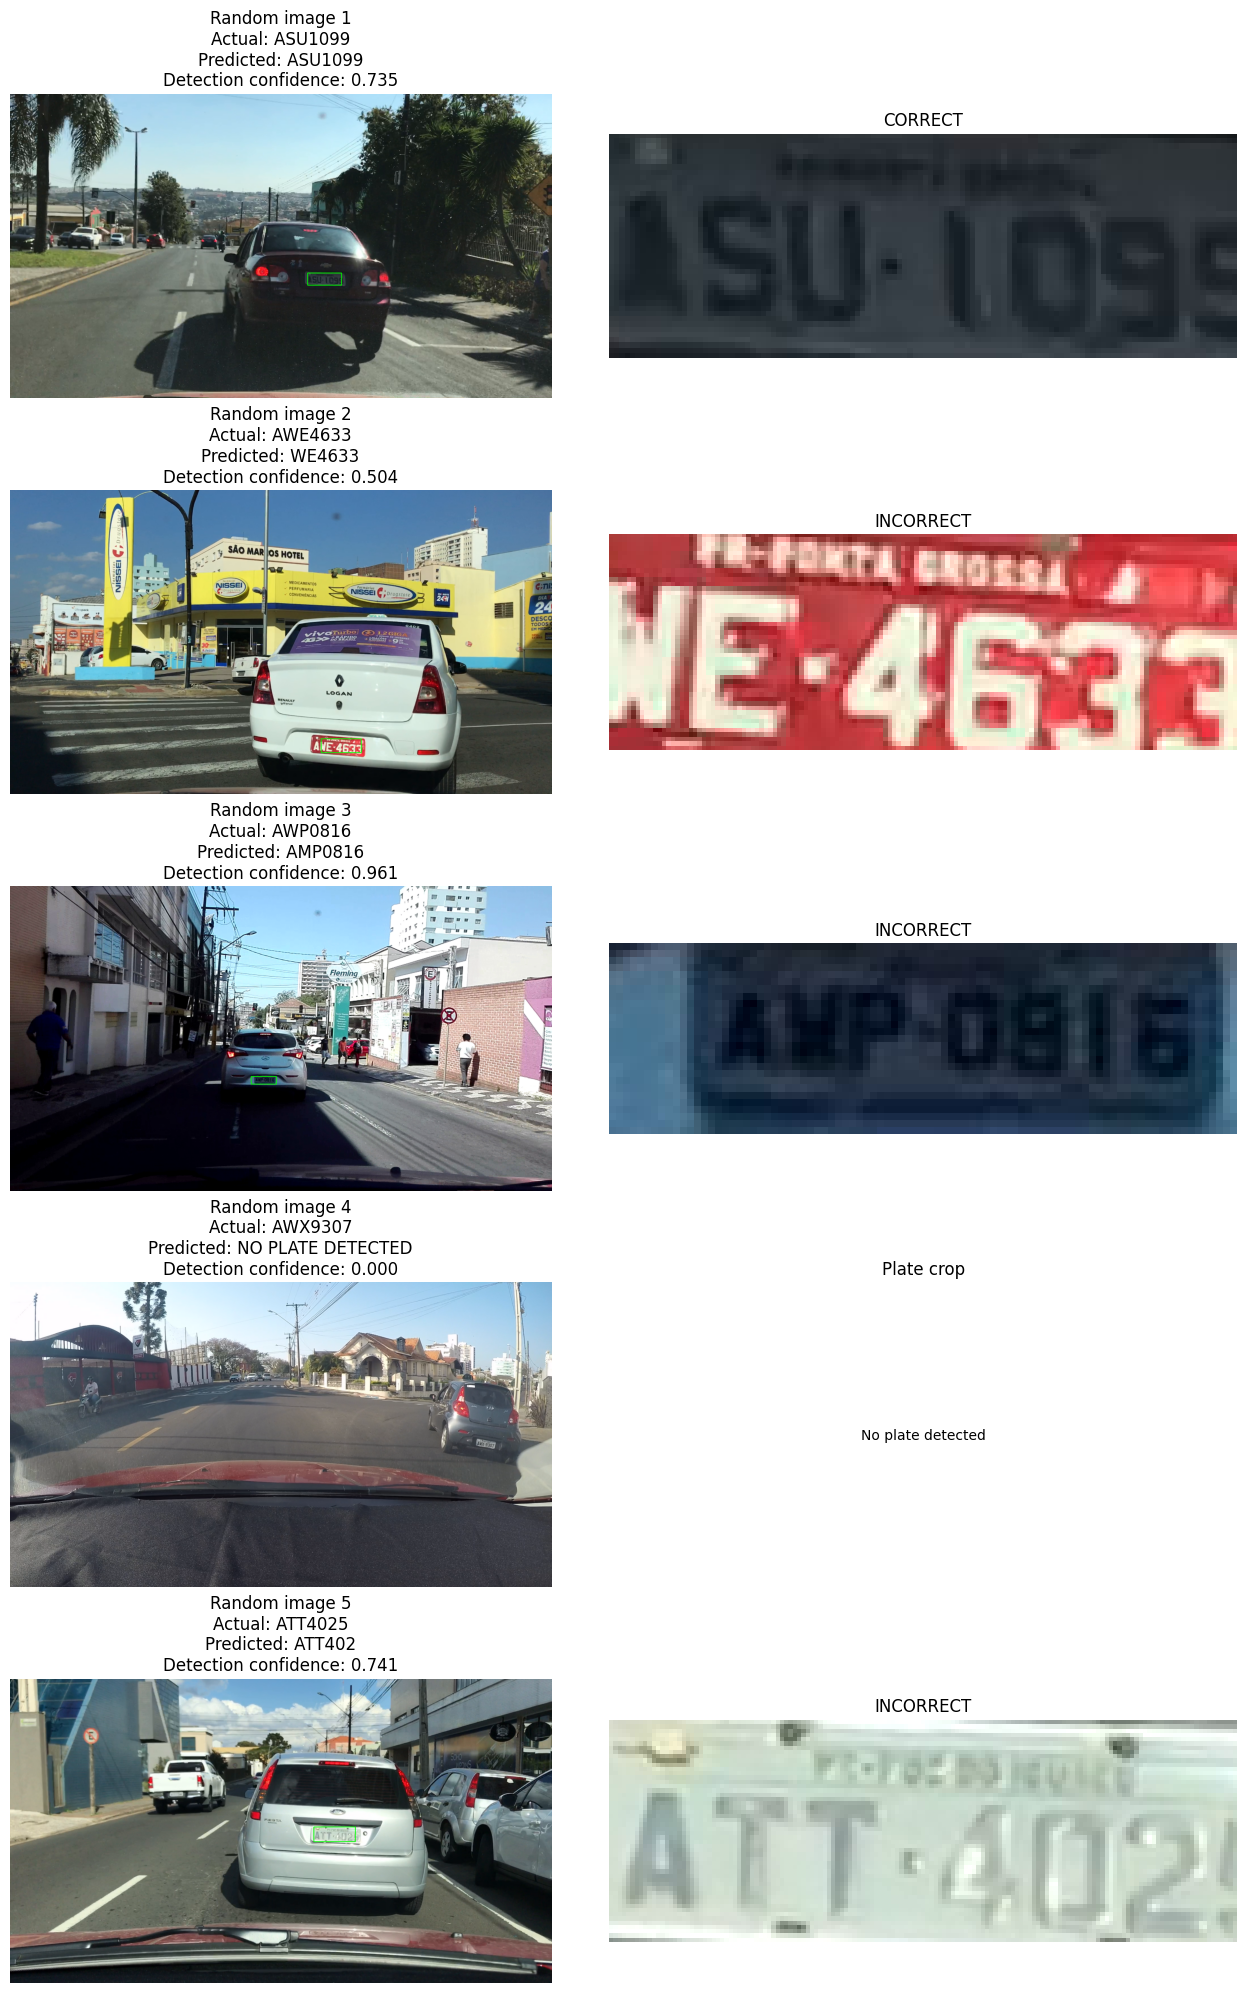


SSD300 + PARSeq random demo results
track0137__track0137[06].png | Actual: ASU1099 | Predicted: ASU1099 | Confidence: 0.735 | CORRECT
track0141__track0141[17].png | Actual: AWE4633 | Predicted: WE4633 | Confidence: 0.504 | INCORRECT
track0128__track0128[07].png | Actual: AWP0816 | Predicted: AMP0816 | Confidence: 0.961 | INCORRECT
track0096__track0096[29].png | Actual: AWX9307 | Predicted: NO PLATE DETECTED | Confidence: 0.000 | INCORRECT
track0131__track0131[10].png | Actual: ATT4025 | Predicted: ATT402 | Confidence: 0.741 | INCORRECT

Exact-match accuracy: 1/5 (20.00%)
Report saved to: /content/drive/MyDrive/UFPR_ALPR_Project/ssd/ssd_parseq_random_demo.json


In [33]:

# CELL 6 — Random 5-image demo: SSD300 + fine-tuned PARSeq OCR

import os, glob, random, re, json
import cv2
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.transforms.functional import to_tensor

PROJECT_DIR = PROJECT
PARSEQ_PATH = f"{PROJECT_DIR}/parseq_ocr/parseq_ufpr_best.pt"
SOURCE_DIR = "/content/drive/MyDrive/UFPR-ALPR dataset"
IMAGE_DIR = f"{DATASET}/images/test"
REPORT_PATH = f"{OUTPUT_DIR}/ssd_parseq_random_demo.json"

# Check required models
if "parseq_model" not in globals() or "parseq_transform" not in globals():
    raise RuntimeError("Load the fine-tuned PARSeq model first.")

if "model" not in globals():
    raise RuntimeError("Load the trained SSD300 model first.")

if not os.path.isfile(PARSEQ_PATH):
    raise FileNotFoundError(f"PARSeq checkpoint not found: {PARSEQ_PATH}")

parseq_model = parseq_model.to(DEVICE).eval()
model = model.to(DEVICE).eval()

# Index original dataset annotations
annotation_index = {}
for split in ("training", "validation", "testing"):
    folder = os.path.join(SOURCE_DIR, split)
    if os.path.isdir(folder):
        for txt in glob.glob(os.path.join(folder, "**", "*.txt"), recursive=True):
            annotation_index[os.path.splitext(os.path.basename(txt))[0]] = txt

def actual_plate(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    for name in (stem, stem.split("__", 1)[-1]):
        txt = annotation_index.get(name)
        if txt:
            with open(txt, encoding="utf-8") as f:
                for line in f:
                    if line.strip().lower().startswith("plate:"):
                        return line.split(":", 1)[1].strip().upper()
    return "NOT FOUND"

def norm_plate(s):
    return re.sub(r"[^A-Z0-9]", "", str(s).upper())

def ocr_plate(crop):
    pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    x = parseq_transform(pil).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        logits = parseq_model(x)
        decoded = parseq_model.tokenizer.decode(logits.softmax(dim=-1))

    texts = decoded[0]
    return str(texts[0] if isinstance(texts, (list, tuple)) else texts).strip().upper()

# Find test images
paths = []
for ext in ("*.png", "*.jpg", "*.jpeg", "*.bmp"):
    paths.extend(glob.glob(os.path.join(IMAGE_DIR, ext)))

paths = sorted(set(paths))
if not paths:
    raise FileNotFoundError(f"No images found in {IMAGE_DIR}")

# Choose five random images (different selection on each run)
samples = random.sample(paths, min(5, len(paths)))
records = []

fig, axes = plt.subplots(len(samples), 2, figsize=(13, 4 * len(samples)))
if len(samples) == 1:
    axes = [axes]

for i, path in enumerate(samples):
    img = cv2.imread(path)
    if img is None:
        axes[i][0].axis("off")
        axes[i][1].axis("off")
        continue

    actual = actual_plate(path)
    display_img = img.copy()
    predicted = "NO PLATE DETECTED"
    crop = None
    score = 0.0

    # SSD300 detection
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    x = to_tensor(Image.fromarray(rgb)).to(DEVICE)

    with torch.inference_mode():
        out = model([x])[0]

    keep = out["scores"] >= 0.50
    if keep.any():
        ids = torch.where(keep)[0]
        idx = ids[out["scores"][ids].argmax()].item()
        score = float(out["scores"][idx].item())

        x1, y1, x2, y2 = map(
            int, out["boxes"][idx].detach().cpu().tolist()
        )

        h, w = img.shape[:2]
        x1, x2 = max(0, x1), min(w, x2)
        y1, y2 = max(0, y1), min(h, y2)

        if x2 > x1 and y2 > y1:
            crop = img[y1:y2, x1:x2]
            predicted = ocr_plate(crop)
            cv2.rectangle(display_img, (x1, y1), (x2, y2), (0, 255, 0), 2)

    correct = (
        actual != "NOT FOUND"
        and predicted != "NO PLATE DETECTED"
        and norm_plate(actual) == norm_plate(predicted)
    )

    records.append({
        "image": os.path.basename(path),
        "actual": actual,
        "predicted": predicted,
        "detection_confidence": round(score, 4),
        "exact_match": bool(correct)
    })

    axes[i][0].imshow(cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB))
    axes[i][0].set_title(
        f"Random image {i+1}\nActual: {actual}\n"
        f"Predicted: {predicted}\nDetection confidence: {score:.3f}"
    )
    axes[i][0].axis("off")

    if crop is not None:
        axes[i][1].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        axes[i][1].set_title("CORRECT" if correct else "INCORRECT")
    else:
        axes[i][1].text(0.5, 0.5, "No plate detected",
                        ha="center", va="center")
        axes[i][1].set_title("Plate crop")

    axes[i][1].axis("off")

plt.tight_layout()
plt.show()

print("\nSSD300 + PARSeq random demo results")
for r in records:
    status = "CORRECT" if r["exact_match"] else "INCORRECT"
    print(
        f"{r['image']} | Actual: {r['actual']} | "
        f"Predicted: {r['predicted']} | "
        f"Confidence: {r['detection_confidence']:.3f} | {status}"
    )

valid = [r for r in records if r["actual"] != "NOT FOUND"]
if valid:
    correct_count = sum(r["exact_match"] for r in valid)
    print(
        f"\nExact-match accuracy: {correct_count}/{len(valid)} "
        f"({100 * correct_count / len(valid):.2f}%)"
    )
else:
    print("\nAccuracy not calculated: ground-truth annotations were not matched.")

os.makedirs(OUTPUT_DIR, exist_ok=True)
with open(REPORT_PATH, "w", encoding="utf-8") as f:
    json.dump(records, f, indent=2)

print("Report saved to:", REPORT_PATH)


## Comparison notes

- Use the same held-out test split and the same fine-tuned PARSeq checkpoint for YOLOv8, Faster R-CNN, and SSD.
- Five images are a demo only; report final metrics on the full test split.
- Checkpoints are saved to Google Drive during training. If Colab disconnects, rerun setup and load `ssd300_plate_best.pth`.
- This notebook selects the best model by validation loss. For rigorous comparison, also evaluate detector precision/recall/mAP and full-pipeline exact plate accuracy/character accuracy and latency.